# Lab 2. Why random splits flatter your map

In Lab 1 you trained a classifier and tested it on a random 30% of your training pixels. The accuracy looked
excellent. In this practical you will find out how much of that accuracy is real.

Nearby places tend to look alike. This is spatial autocorrelation, and it means that a test pixel next to a training
pixel is not a fair test. The lab follows the validation design of Bıçakçı (2026), *Photogrammetric Engineering &
Remote Sensing*, in press, where test areas were locked away in spatial blocks before any model was fitted. In that
study a random split would have lifted a model that used no satellite data at all from R² 0.03 to 0.32.

**Learning outcomes.** By the end of the lab you should be able to
1. explain why spatial autocorrelation breaks the independence that a random test set assumes,
2. run grouped and spatially blocked cross-validation,
3. interpret the gap between random and spatial accuracy estimates,
4. test whether errors cluster in space with Moran's I.

**Level and time.** Honours (SCQF level 10) or MSc (SCQF level 11), about two hours. Run Lab 1 first, because this
lab reuses its training pixels.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict, train_test_split
from sklearn.metrics import accuracy_score, f1_score
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore", category=FutureWarning)
# Within each 5 by 5 square, a pixel's nearest neighbours all lie in the same square. libpysal warns that the
# neighbour graph falls apart into one piece per square. That is the point of section 2, so the warning is silenced.
warnings.filterwarnings("ignore", message="The weights matrix is not fully connected")
DATA = Path("../data")
FIGURES = Path("../figures")
FEATURES = ["B02", "B03", "B04", "B08", "B11", "B12", "NDVI", "NDBI", "MNDWI", "VV_dB", "VH_dB"]
CLASSES = {1: "sealed", 2: "green", 3: "water"}

train = pd.read_csv(DATA / "lab1_training_pixels.csv")
polygons = gpd.read_file(DATA / "training_polygons.gpkg", layer="training_polygons")
X = train[FEATURES].values
XY = train[["E", "N"]].values
y = train["label"].values
print(f"{len(train)} training pixels in {train.polygon_id.nunique()} squares")

forest = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

def evaluate(features, cv, groups=None):
    """Cross-validated overall accuracy and macro F1 for one feature set and one splitting scheme."""
    predicted = cross_val_predict(forest, features, y, cv=cv, groups=groups)
    return accuracy_score(y, predicted), f1_score(y, predicted, average="macro"), predicted

def blocks(size_m):
    """Label each pixel with the square block of the given size that contains it."""
    return (train.E // size_m).astype(int).astype(str) + "_" + (train.N // size_m).astype(int).astype(str)

3340 training pixels in 140 squares


## 1. The Lab 1 result again

First we repeat the random 70 and 30 split from Lab 1, so that we have the number to beat.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
random_split = accuracy_score(y_test, forest.fit(X_train, y_train).predict(X_test))
print(f"Random 30% test set, overall accuracy {random_split:.3f}")

Random 30% test set, overall accuracy 0.977


## 2. How alike are neighbouring pixels?

Moran's I measures whether values at nearby locations are more similar than chance. It runs from about minus 1
(neighbours differ) through 0 (no pattern) to plus 1 (neighbours are alike). We compute it for NDVI at the training
pixels, with each pixel's eight nearest pixels as its neighbours.

**Predict.** Will Moran's I for NDVI be close to 0, or close to 1?

In [3]:
weights = KNN.from_array(XY, k=8)
weights.transform = "r"
moran_ndvi = Moran(train["NDVI"].values, weights, permutations=999)
print(f"Moran's I for NDVI {moran_ndvi.I:.2f}, pseudo p-value {moran_ndvi.p_sim:.3f}")

Moran's I for NDVI 0.94, pseudo p-value 0.001


**Investigate.** Each pixel's eight nearest neighbours sit inside its own 50 m square. A value this high means that
most test pixels in Lab 1 had a near copy in the training set. The model could pass the test by recognising places
it had already seen.

## 3. Fairer tests. Hold out whole squares or whole blocks

We now use five-fold cross-validation in three ways.
- **Random pixels.** Any pixel can be in any fold, as in Lab 1.
- **By square.** All pixels of a training square stay in the same fold, so the model is always tested on squares it
  has never seen.
- **1 km blocks.** All pixels in the same 1 by 1 km block of the National Grid stay together, so the test areas are
  also some distance from the training areas.

**Predict.** Rank the three schemes from highest to lowest accuracy.

In [4]:
schemes = {
    "random pixels": (KFold(5, shuffle=True, random_state=42), None),
    "by square": (GroupKFold(5), train["polygon_id"].values),
    "1 km blocks": (GroupKFold(5), blocks(1000).values),
}
results = []
for name, (cv, groups) in schemes.items():
    accuracy, macro_f1, _ = evaluate(X, cv, groups)
    results.append({"model": "Sentinel-1 and Sentinel-2", "scheme": name,
                    "overall accuracy": round(accuracy, 3), "macro F1": round(macro_f1, 3)})
pd.DataFrame(results)

,model,scheme,overall accuracy,macro F1
0,Sentinel-1 and Sentinel-2,random pixels,0.981,0.984
1,Sentinel-1 and Sentinel-2,by square,0.963,0.963
2,Sentinel-1 and Sentinel-2,1 km blocks,0.957,0.957


## 4. A model that never sees the satellite

Now a thought experiment. We train the same random forest on nothing but the easting and northing of each pixel.
This model knows where a pixel is and nothing about what the satellite saw there.

**Predict.** How accurate will this model be under each scheme? Write down three numbers.

In [5]:
for name, (cv, groups) in schemes.items():
    accuracy, macro_f1, _ = evaluate(XY, cv, groups)
    results.append({"model": "coordinates only", "scheme": name,
                    "overall accuracy": round(accuracy, 3), "macro F1": round(macro_f1, 3)})
table = pd.DataFrame(results)
table

,model,scheme,overall accuracy,macro F1
0,Sentinel-1 and Sentinel-2,random pixels,0.981,0.984
1,Sentinel-1 and Sentinel-2,by square,0.963,0.963
2,Sentinel-1 and Sentinel-2,1 km blocks,0.957,0.957
3,coordinates only,random pixels,1.000,1.000
4,coordinates only,by square,0.631,0.594
5,coordinates only,1 km blocks,0.604,0.578


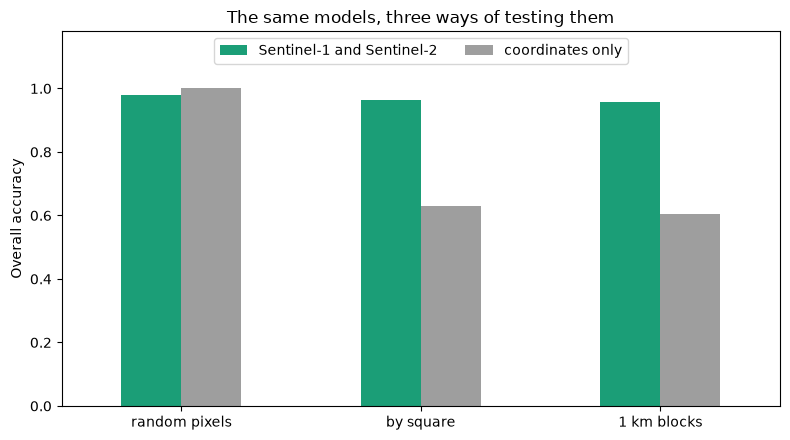

In [6]:
MODEL_COLOURS = {"Sentinel-1 and Sentinel-2": "#1b9e77", "coordinates only": "#9e9e9e"}
pivot = table.pivot(index="scheme", columns="model", values="overall accuracy").loc[list(schemes), list(MODEL_COLOURS)]
ax = pivot.plot.bar(figsize=(8, 4.5), color=MODEL_COLOURS, rot=0)
ax.set_xlabel("")
ax.set_ylabel("Overall accuracy")
ax.set_ylim(0, 1.18)
ax.set_title("The same models, three ways of testing them")
ax.legend(title="", loc="upper center", ncol=2)
plt.tight_layout()
plt.savefig(FIGURES / "lab2_validation_schemes.png", dpi=120)
plt.show()

**Investigate.**
1. Under random pixels the coordinates-only model looks as good as, or better than, the satellite model. Why?
2. What happens to it once whole squares or blocks are held out?
3. Which of the numbers in the table would you report in a paper, and why?

## 5. Does the block size matter?

Bigger blocks push test areas further from training areas. We repeat the blocked test for blocks of 250 m to 4 km.

**Predict.** Sketch how each model's accuracy will change as the blocks grow.

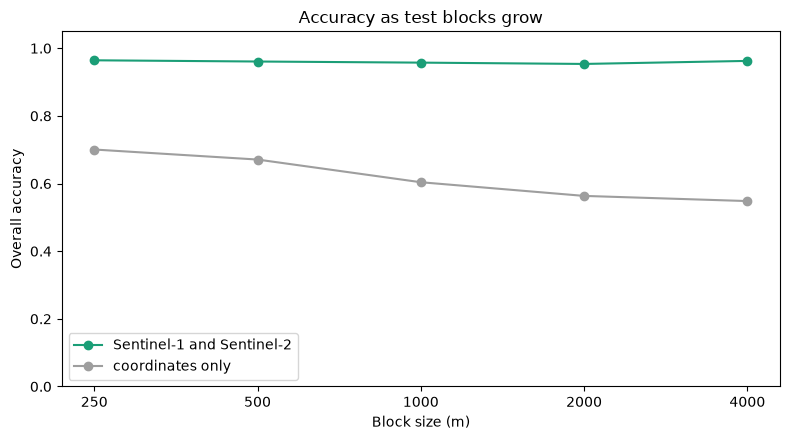

model,Sentinel-1 and Sentinel-2,coordinates only
block size (m),,
250,0.964,0.701
500,0.961,0.671
1000,0.957,0.604
2000,0.954,0.563
4000,0.963,0.548


In [7]:
sizes = [250, 500, 1000, 2000, 4000]
curve = []
for size in sizes:
    for model, features in [("Sentinel-1 and Sentinel-2", X), ("coordinates only", XY)]:
        accuracy, _, _ = evaluate(features, GroupKFold(5), blocks(size).values)
        curve.append({"block size (m)": size, "model": model, "overall accuracy": accuracy})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(8, 4.5))
for model, colour in MODEL_COLOURS.items():
    part = curve[curve.model == model]
    ax.plot(part["block size (m)"], part["overall accuracy"], marker="o", color=colour, label=model)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks(sizes)
ax.set_xticklabels([str(s) for s in sizes])
ax.set_xlabel("Block size (m)")
ax.set_ylabel("Overall accuracy")
ax.set_ylim(0, 1.05)
ax.legend()
ax.set_title("Accuracy as test blocks grow")
plt.tight_layout()
plt.savefig(FIGURES / "lab2_block_size.png", dpi=120)
plt.show()
curve.pivot(index="block size (m)", columns="model", values="overall accuracy").round(3)

## 6. Where are the errors?

Finally we look at the errors of the satellite model under the 1 km block test. For each training square we compute
the share of its pixels that were misclassified, map it and ask whether squares with errors sit near each other.

**Predict.** Will the errors be scattered at random, or clustered in particular parts of the study area?

Squares with at least one error 32 of 140
Moran's I for square error rates 0.05, pseudo p-value 0.099


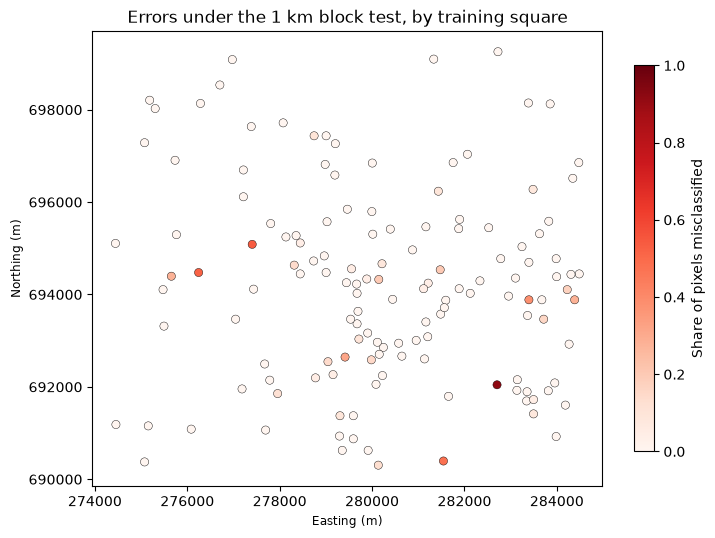

,mean error rate
class,
green,0.061
sealed,0.029
water,0.034


In [8]:
_, _, block_predicted = evaluate(X, GroupKFold(5), blocks(1000).values)
train["error"] = (block_predicted != y).astype(int)
per_square = train.groupby("polygon_id")["error"].mean().rename("error_rate")
squares = polygons.merge(per_square, on="polygon_id")
squares["centroid"] = squares.geometry.centroid
centroid_xy = np.c_[squares.centroid.x, squares.centroid.y]
w_squares = KNN.from_array(centroid_xy, k=6)
w_squares.transform = "r"
moran_errors = Moran(squares["error_rate"].values, w_squares, permutations=999)
print(f"Squares with at least one error {int((squares.error_rate > 0).sum())} of {len(squares)}")
print(f"Moran's I for square error rates {moran_errors.I:.2f}, pseudo p-value {moran_errors.p_sim:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 6))
squares.set_geometry("centroid").plot(ax=ax, column="error_rate", cmap="Reds", legend=True, markersize=35,
                                      edgecolor="black", linewidth=0.3, vmin=0, vmax=1,
                                      legend_kwds={"label": "Share of pixels misclassified", "shrink": 0.7})
ax.set_title("Errors under the 1 km block test, by training square")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
plt.show()
squares.groupby("class")["error_rate"].mean().round(3).to_frame("mean error rate")

**Investigate.** Which class carries most of the errors? If Moran's I is not significant, the errors are not
clustered at this scale. What would a significant positive value have told you about where to collect more training
data?

## 7. Optional extension. AlphaEarth satellite embeddings

Google DeepMind's AlphaEarth Foundations model summarises a year of satellite observations as 64 numbers for every
10 m pixel. In Bıçakçı (2026) these embeddings matched standard Sentinel-2 products for street greenery. Here you can
test whether they classify Stirling's surfaces better than the bands and indices from Lab 1, under the fair 1 km
block test.

This section needs a free Google Earth Engine account and a Cloud project. Set the environment variable
`EE_PROJECT` to your project before starting Jupyter. Without it the section is skipped.

In [9]:
EE_PROJECT = os.environ.get("EE_PROJECT")
if not EE_PROJECT:
    print("Optional extension skipped. Set EE_PROJECT to run it.")
else:
    import ee
    from pyproj import Transformer

    ee.Initialize(project=EE_PROJECT)
    to_lonlat = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy=True)
    lon, lat = to_lonlat.transform(train.E.values, train.N.values)
    embedding = (ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
                 .filterDate("2025-01-01", "2026-01-01").mosaic())
    bands = [f"A{i:02d}" for i in range(64)]
    samples = []
    for start in range(0, len(train), 1000):
        chunk = ee.FeatureCollection([
            ee.Feature(ee.Geometry.Point([float(lon[i]), float(lat[i])]), {"pixel": int(i)})
            for i in range(start, min(start + 1000, len(train)))
        ])
        info = embedding.sampleRegions(collection=chunk, scale=10, geometries=False).getInfo()
        samples.extend(feature["properties"] for feature in info["features"])
    emb = pd.DataFrame(samples).set_index("pixel").sort_index()
    keep = emb.index.values
    X_emb = emb[bands].values
    groups = blocks(1000).values[keep]
    comparison = []
    for name, features in [("Sentinel bands and indices", X[keep]), ("AlphaEarth embeddings", X_emb),
                           ("both together", np.c_[X[keep], X_emb])]:
        predicted = cross_val_predict(forest, features, y[keep], cv=GroupKFold(5), groups=groups)
        comparison.append({"features": name,
                           "overall accuracy": round(accuracy_score(y[keep], predicted), 3),
                           "macro F1": round(f1_score(y[keep], predicted, average="macro"), 3)})
    print(f"Embeddings found for {len(keep)} of {len(train)} pixels")
    display(pd.DataFrame(comparison))

Embeddings found for 3340 of 3340 pixels


,features,overall accuracy,macro F1
0,Sentinel bands and indices,0.957,0.957
1,AlphaEarth embeddings,0.980,0.980
2,both together,0.981,0.982


## 8. Make and reflect

**Make.** Rerun Labs 1 and 2 for your own town from the assessment brief, and report both the random split and the
1 km block result.

**Reflect.**
1. In your own words, why does a random split flatter a map?
2. Our labels and our images both come from Sentinel data. Could a model score well against WorldCover and still be
   wrong on the ground? How would you check?
3. A planning officer wants a map of sealed surfaces for a town 50 km away. Which accuracy figure from this lab would
   you give them, and what would you add to it?